# BT4012 Kaggle Competition
This notebook rebuilds both submissions I selected from the four raw competition files
(placed in `data/`): data checks, preprocessing, feature engineering, temporal validation, the final models and the
two submission files `M26_M18_M24_1to1.csv` (final) and `M21_M18_M19_1to1.csv` (second selection).

**Task.** Rank Bitcoin transactions by how likely they are to be illicit (metric: ROC-AUC). Training data covers
time steps 1–35; the test set is steps **36–49**, i.e. entirely in the future.

**Final model.** An equal-weight rank-average of two ensembles:
* **Model A, binary graph ensemble:** LightGBM + CatBoost on the raw features plus aggregates of each
  transaction's *labelled* neighbours. Unlabelled training transactions from the most recent 15 steps are
  added as weak licit examples, and labelled licit rows that resemble ordinary traffic get more weight.
* **Model B, 3-class ensemble:** LightGBM + CatBoost that learn licit / illicit / unknown as three classes.

Each model has four members (2 libraries × {all features, drift-pruned features}).

**Main development steps** (public score = ROC-AUC on the public 30% of the hidden test set):

| Step | CV (late folds) | Public score |
|---|---|---|
| Baseline: LightGBM on the 165 raw features | 0.9973 | 0.94499 |
| Unlabelled rows as weak *illicit* (PU learning) | 0.9944 | 0.93169 |
| Unlabelled rows as weak *licit* (w = 0.01) | 0.9978 | 0.95282 |
| 4-model ensemble, weak licit (w = 0.05) | 0.9987 | 0.96024 |
| + only the 15 most recent steps of unlabelled rows | 0.9988 | 0.96273 |
| + licit importance weights | 0.9987 | 0.96361 |
| + labelled-neighbour graph features (**Model A**) | 0.9985 | 0.96576 |
| 3-class model, single LightGBM | 0.9973 | 0.96462 |
| Model A + single 3-class LightGBM | 0.9983 | 0.96805 |
| **Model A + Model B (3-class 4-model ensemble): this notebook** | **0.9986** | **0.96843** |


In [1]:
import time
import warnings
from pathlib import Path

import catboost
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from scipy.stats import ks_2samp
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore")
DATA_DIR = Path("data")                       # folder with the four Kaggle files (train, test, edge list, sample submission)
OUT_FINAL = Path("M26_M18_M24_1to1.csv")      # final submission: Model A + Model B
OUT_SECOND = Path("M21_M18_M19_1to1.csv")     # second selected submission: Model A + single 3-class LightGBM
RUN_CV = True        # False skips all validation and only builds the two submission files (~15 min instead of ~1h30)

SEEDS = [0, 1, 2, 3, 4]   # binary models are averaged over 5 seeds (single-seed CV moves by ~0.0015)
N_DRIFT = 15              # features removed in the drift-pruned members
UNK_WEIGHT = 0.05         # total weight of unlabelled rows = 0.05 x (number of unlabelled rows in the window)
RECENT = 15               # only unlabelled rows from the last 15 training steps are used
ALPHA = 1.0               # 3-class score: p_ill / (p_ill + p_lic + ALPHA * p_unk)
LGB_PARAMS = dict(n_estimators=600, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
                  n_jobs=8, verbose=-1, deterministic=True, force_row_wise=True)
CAT_PARAMS = dict(iterations=1000, learning_rate=0.05, depth=6, l2_leaf_reg=3.0,
                  verbose=0, thread_count=8, allow_writing_files=False)
print("lightgbm", lgb.__version__, "| catboost", catboost.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

lightgbm 4.7.0 | catboost 1.2.7 | pandas 3.0.6 | numpy 1.26.4


## 1. Data
* `train.csv`: steps 1–35, `label` = 1 illicit, 0 licit, blank = unknown.
* `test.csv`: steps 36–49, no labels.
* `txs_edgelist.csv`: payment flows; A→B means an output of A is spent by B.

All 165 features are anonymised and standardised, so what each one measures is not given.

Train and test are stacked into one table `nodes` (train rows first) so graph features can be computed once.

In [2]:
FEATS = [f"feat_{i}" for i in range(1, 166)]
LOCAL_FEATS = FEATS[:93]
dtypes = {f: np.float32 for f in FEATS}
train = pd.read_csv(DATA_DIR / "train.csv", dtype=dtypes)
test = pd.read_csv(DATA_DIR / "test.csv", dtype=dtypes)
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")

cols = ["txId", "time_step", *FEATS, "label", "is_test", "test_index"]
nodes = pd.concat([train.assign(is_test=False, test_index=-1)[cols],
                   test.rename(columns={"index": "test_index"}).assign(is_test=True, label=np.nan)[cols]],
                  ignore_index=True)
nodes["time_step"] = nodes["time_step"].astype(np.int16)
nodes["label"] = nodes["label"].astype(np.float32)
nodes["test_index"] = nodes["test_index"].astype(np.int32)

y_all = nodes["label"].to_numpy()
ts = nodes["time_step"].to_numpy()
te = nodes["is_test"].to_numpy()
labelled = ~np.isnan(y_all)            # labelled training rows (test labels are hidden)
unknown = np.isnan(y_all) & ~te        # unlabelled training rows
order = np.argsort(nodes.loc[te, "test_index"].to_numpy())   # test rows -> submission order
test_index = np.sort(nodes.loc[te, "test_index"].to_numpy())

print("train", train.shape, "| test", test.shape, "| edges", edges.shape)
print(train.label.map({0: "licit", 1: "illicit"}).fillna("unknown").value_counts().to_dict())
print("missing feature values:", int(nodes[FEATS].isna().sum().sum()), "| duplicate txIds:", int(nodes.txId.duplicated().sum()))

train (141772, 168) | test (15329, 168) | edges (234355, 2)
{'unknown': 110537, 'licit': 27591, 'illicit': 3644}
missing feature values: 0 | duplicate txIds: 0


### 1.1 Two facts about the data that drive most of the design
1. **The test file only has labelled transactions.** The unknown transactions of steps 36–49 were left out, but
   their edges are still in the edge list. In training, about 70% of a transaction's neighbours are unknown
   transactions *with* features; in test, many neighbours simply have no row.
2. **No edge crosses time steps**, so labels cannot leak from training steps into test steps through the graph.

In [3]:
ts_of = nodes.set_index("txId").time_step
k1, k2 = edges.txId1.isin(ts_of.index), edges.txId2.isin(ts_of.index)
both = k1 & k2
print("edges with both ends present:", int(both.sum()), "| edges with a missing end:", int((~both).sum()))
print("edges crossing time steps   :", int((ts_of.reindex(edges.txId1[both]).values != ts_of.reindex(edges.txId2[both]).values).sum()))

ids = pd.concat([edges.txId1, edges.txId2]); other = pd.concat([edges.txId2, edges.txId1])
deg = ids.value_counts(); deg_present = ids[other.isin(ts_of.index).values].value_counts()
for name, m in [("train labelled, steps 26-35", labelled & (ts >= 26)), ("test, steps 36-49", te)]:
    t = nodes.txId[m]
    print(f"{name:28s}: edges per tx {deg.reindex(t).fillna(0).mean():.2f} | neighbours with a feature row "
          f"{deg_present.reindex(t).fillna(0).mean():.2f}")

edges with both ends present: 175918 | edges with a missing end: 58437
edges crossing time steps   : 0
train labelled, steps 26-35 : edges per tx 2.79 | neighbours with a feature row 2.79
test, steps 36-49           : edges per tx 3.24 | neighbours with a feature row 1.66


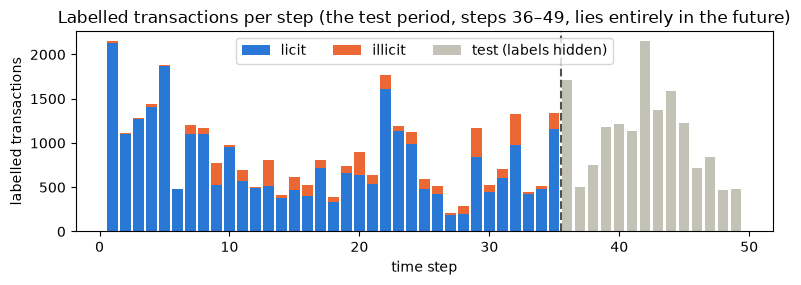

illicit share of labelled training rows: 0.117


In [4]:
lab_tr = nodes[labelled]
counts = lab_tr.groupby(["time_step", "label"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.bar(counts.index, counts[0.0], color="#2a78d6", label="licit")
ax.bar(counts.index, counts[1.0], bottom=counts[0.0], color="#eb6834", label="illicit")
tc = nodes[te].groupby("time_step").size()
ax.bar(tc.index, tc.values, color="#c3c2b7", label="test (labels hidden)")
ax.axvline(35.5, ls="--", c="#52514e")
ax.set_xlabel("time step"); ax.set_ylabel("labelled transactions"); ax.legend(ncol=3)
ax.set_title("Labelled transactions per step (the test period, steps 36–49, lies entirely in the future)")
plt.show()
print(f"illicit share of labelled training rows: {lab_tr.label.mean():.3f}")

## 2. Preprocessing and feature engineering
* **Missing values / duplicates:** none (checked above). Tree models don't need scaling.
* **`time_step` is not a feature.** Test steps never appear in training, so a tree would treat all of them as
  "step 35".
* **Class imbalance (11.7% illicit):** left as is. AUC only depends on the ranking, and balanced class weights
  made almost no difference in validation (CV 0.9975 vs 0.9973) while lowering the long-horizon fold (0.895 vs 0.901);
  see the comparison in §4.1.

### 2.1 Drift-pruned feature set
For every feature I compare its distribution in the most recent labelled training steps (26–35) with the test
period, using the Kolmogorov–Smirnov statistic (this uses test *features* only, never labels). The 15 most-shifted
features are removed in two of the four members of each ensemble. The top six are essentially clocks
(|ρ| of about 0.9 or higher with time). Dropping them on their own did not help (public score 0.943 vs 0.945), but as a second "view" next to
the full feature set it adds useful diversity.

In [5]:
late = nodes[labelled & (ts >= 26)]
ks = pd.Series({f: ks_2samp(late[f], nodes.loc[te, f]).statistic for f in FEATS}).sort_values(ascending=False)
DRIFT = list(ks.index[:N_DRIFT])
print("most-shifted features (KS):", ks.head(N_DRIFT).round(3).to_dict())
rho = nodes.loc[~te, ["time_step", *DRIFT[:6]]].corr(method="spearman")["time_step"].drop("time_step")
print("Spearman correlation of the top 6 with time:", rho.round(3).to_dict())

most-shifted features (KS): {'feat_101': 0.995, 'feat_103': 0.994, 'feat_100': 0.992, 'feat_136': 0.987, 'feat_139': 0.874, 'feat_137': 0.826, 'feat_2': 0.476, 'feat_109': 0.35, 'feat_106': 0.344, 'feat_107': 0.324, 'feat_142': 0.257, 'feat_115': 0.247, 'feat_113': 0.238, 'feat_151': 0.236, 'feat_149': 0.233}
Spearman correlation of the top 6 with time: {'feat_101': 0.997, 'feat_103': 0.995, 'feat_100': 0.992, 'feat_136': 0.994, 'feat_139': 0.954, 'feat_137': 0.896}


### 2.2 Graph features that mean the same thing in train and test
Averaging over *all* neighbours would be computed over ~3 neighbours in training but only over the labelled ones in
test (fact 1 above), so the model would be scored on a different feature than it learned. I therefore aggregate
**labelled neighbours only** (labelled training transactions and test transactions), which exist in both periods.

For each transaction, separately for senders (predecessors) and receivers (successors): the mean and max of the
first 93 features (`feat_1`–`feat_93`) of its labelled neighbours, plus how many labelled neighbours it has. That is 2 × (93 + 93 + 1)
= 374 new columns, 539 in total.

I also tried structural features (degree, PageRank, DAG depth, k-core, 2-hop counts). They did not
improve the main folds (CV 0.9974 vs 0.9973) and lowered the long-horizon fold (0.880 vs 0.901), so they were dropped.

In [6]:
def labelled_neighbour_features(nodes, edges, cols=LOCAL_FEATS):
    e = edges.drop_duplicates()
    ids = pd.Index(pd.unique(np.concatenate([nodes.txId.to_numpy(), e.txId1.to_numpy(), e.txId2.to_numpy()])))
    s, d = ids.get_indexer(e.txId1), ids.get_indexer(e.txId2)
    pos = ids.get_indexer(nodes.txId)
    is_lab = np.zeros(len(ids), bool)
    is_lab[pos[(nodes.label.notna() | nodes.is_test).to_numpy()]] = True   # rows whose label is (or will be) known
    X = np.full((len(ids), len(cols)), np.nan, dtype=np.float32)
    X[pos] = nodes[cols].to_numpy()
    out = pd.DataFrame(index=range(len(ids)))
    for direction, me, nb in (("pred", d, s), ("succ", s, d)):
        keep = is_lab[nb]
        vals = pd.DataFrame(X[nb[keep]], columns=cols)
        vals["_me"] = me[keep]
        g = vals.groupby("_me")
        out = (out.join(g[cols].mean().add_prefix(f"{direction}L_mean_"))
                  .join(g[cols].max().add_prefix(f"{direction}L_max_"))
                  .join(g.size().rename(f"n_{direction}_labelled")))
        out[f"n_{direction}_labelled"] = out[f"n_{direction}_labelled"].fillna(0)
    return out.iloc[pos].reset_index(drop=True).astype(np.float32)

t0 = time.time()
GRAPH = labelled_neighbour_features(nodes, edges)
X = pd.concat([nodes[FEATS].reset_index(drop=True), GRAPH], axis=1)    # 165 raw + 374 graph columns
G_ALL = list(X.columns)
G_PRUNED = [c for c in G_ALL if c not in DRIFT]
FEATS_PRUNED = [c for c in FEATS if c not in DRIFT]
print(X.shape, f"({time.time() - t0:.0f}s)")
print("test rows with no labelled neighbour at all:",
      f"{((GRAPH.n_pred_labelled + GRAPH.n_succ_labelled)[te] == 0).mean():.2f}")

(157101, 539) (1s)
test rows with no labelled neighbour at all: 0.25


## 3. Validation design
Every fold trains on earlier steps and validates on later ones, using labelled rows only (like the test set).
The final model is trained on steps 1–35, so the main folds also train on as much recent data as possible:

| Fold | Train steps | Validate steps | Role |
|---|---|---|---|
| L1 | 1–25 | 26–35 | CV score |
| L2 | 1–28 | 29–35 | CV score |
| L3 | 1–30 | 31–35 | CV score |
| L4 | 1–32 | 33–35 | CV score |
| H  | 1–21 | 22–35 | stress test only (14-step horizon) |

**CV = mean ROC-AUC over L1–L4.** Before spending a Kaggle submission I also compared candidates with a paired
bootstrap over validation rows and only submitted when the new model won in at least 80% of resamples.

*What went wrong first.* My first CV averaged early folds (training on steps 1–20) with late ones. It said PU
learning was the best idea, and the leaderboard disagreed (public score 0.932 vs 0.945). The late folds agree with the
leaderboard's ordering, so I switched to them. They are still almost blind to the labelling shift described in
§4, so the decisions in §4 were confirmed with one deliberate change per submission.

In [7]:
FOLDS = {"L1": (range(1, 26), range(26, 36)), "L2": (range(1, 29), range(29, 36)),
         "L3": (range(1, 31), range(31, 36)), "L4": (range(1, 33), range(33, 36)),
         "H": (range(1, 22), range(22, 36))}
PRIMARY = ["L1", "L2", "L3", "L4"]

def summarise(oof):
    # oof has columns fold, txId, y, pred -> fold AUCs, CV, worst fold and average precision
    auc = {f: roc_auc_score(g.y, g.pred) for f, g in oof.groupby("fold", sort=False)}
    ap = {f: average_precision_score(g.y, g.pred) for f, g in oof.groupby("fold", sort=False)}
    return {"CV": np.mean([auc[f] for f in PRIMARY]), "worst": min(auc[f] for f in PRIMARY),
            **{f: auc[f] for f in auc}, "AP": np.mean([ap[f] for f in PRIMARY])}

def oof_frame(fold, va, pred):
    return pd.DataFrame({"fold": fold, "txId": nodes.txId.to_numpy()[va], "time_step": ts[va],
                         "y": y_all[va].astype(int), "pred": pred})

## 4. The main problem: who gets labelled changes over time
A model trained only on labelled rows learns what labelled licit transactions look like. If those examples are
unusual compared with everyday traffic, the model can end up treating "ordinary-looking" transactions as suspicious.

To check this I train a separate model that only separates **unlabelled from labelled** transactions (it never
sees illicit/licit labels). Six pure time-proxy features are removed first, so the score does not just learn time.
Training rows are scored out-of-fold in blocks of 5 steps. The output shows the pattern: labelled licit
transactions are the least "unlabelled-like", illicit ones more so, and the test transactions look more like
ordinary unlabelled traffic than the labelled training transactions do. The kind of transaction that gets labelled
seems to change over time.

In [8]:
t0 = time.time()
TIME_PROXIES = ["feat_100", "feat_101", "feat_103", "feat_136", "feat_137", "feat_139"]
ULK_FEATS = [f for f in FEATS if f not in TIME_PROXIES]
unk_like = np.full(len(nodes), np.nan)
for block in [range(s, s + 5) for s in range(1, 36, 5)]:
    hold = np.isin(ts, list(block)) & ~te
    fit = ~te & ~hold
    m = LGBMClassifier(**{**LGB_PARAMS, "num_leaves": 31}, random_state=0)
    m.fit(nodes.loc[fit, ULK_FEATS], unknown[fit].astype(int))
    unk_like[hold] = m.predict_proba(nodes.loc[hold, ULK_FEATS])[:, 1]
m = LGBMClassifier(**{**LGB_PARAMS, "num_leaves": 31}, random_state=0)
m.fit(nodes.loc[~te, ULK_FEATS], unknown[~te].astype(int))
unk_like[te] = m.predict_proba(nodes.loc[te, ULK_FEATS])[:, 1]

print(f"({time.time() - t0:.0f}s) mean 'unlabelled-likeness':")
print(f"  all labelled training {unk_like[labelled].mean():.3f} | training licit {unk_like[labelled & (y_all == 0)].mean():.3f} | training illicit "
      f"{unk_like[labelled & (y_all == 1)].mean():.3f} | test {unk_like[te].mean():.3f}")
print(f"  share above 0.5: training labelled (26-35) {(unk_like[labelled & (ts >= 26)] > 0.5).mean():.3f}"
      f" | test {(unk_like[te] > 0.5).mean():.3f}")

(79s) mean 'unlabelled-likeness':
  all labelled training 0.279 | training licit 0.266 | training illicit 0.380 | test 0.297
  share above 0.5: training labelled (26-35) 0.236 | test 0.260


### 4.1 Training rows for the binary models
* labelled illicit → target 1, weight 1;
* labelled licit → target 0, weight = **importance weight**: the odds of the unlabelled-likeness score, square-rooted,
  normalised to mean 1 and clipped to [0.2, 5]. Licit rows that look like ordinary traffic count more;
* **unlabelled rows from the last 15 training steps → target 0** (weak licit). Their total weight equals 0.05 × the
  number of unlabelled rows in the whole window, so each recent row counts more than in the all-steps version.

Why each piece is there (public score, one change at a time):
* unknowns as weak *illicit* (PU learning): 0.945 → **0.932**, rejected;
* unknowns as weak *licit*: 0.945 → 0.953 (w = 0.01) → 0.960 (w = 0.05, 4-model ensemble);
* only the most recent 15 steps of unknowns, same total weight: → 0.963 (older unknowns describe older behaviour);
* licit importance weights: → 0.964.

No test rows or labels are used for training; the test set has no unlabelled rows anyway.

The cell below compares five set-ups with a single LightGBM on the raw features (5 seeds, all folds): the
supervised baseline, the baseline with balanced class weights, PU learning, weak licit with w = 0.01, and the final
recipe. The baseline, PU and weak-licit rows are the same models as in the table at the top. The late folds barely
separate them. Most of the effect is specific to the test period, which is why it was confirmed on the public score.

In [9]:
def training_rows(train_steps, mode="final"):
    # rows, targets and weights for a binary model trained on `train_steps`
    tr = labelled & np.isin(ts, list(train_steps))
    steps = np.unique(ts[tr])
    all_u = unknown & np.isin(ts, steps)
    if mode == "supervised":
        return tr, y_all[tr].astype(int), None
    if mode == "balanced":                                       # both classes get equal total weight
        y = y_all[tr].astype(int)
        return tr, y, np.where(y == 1, 0.5 / y.mean(), 0.5 / (1 - y.mean()))
    if mode in ("pu", "weak_licit"):
        rows = tr | all_u
        target = np.where(unknown[rows], 1 if mode == "pu" else 0, y_all[rows]).astype(int)
        return rows, target, np.where(unknown[rows], 0.002 if mode == "pu" else 0.01, 1.0)
    u = all_u & (ts > steps.max() - RECENT)                      # recent unknowns only ...
    w_u = UNK_WEIGHT * all_u.sum() / max(u.sum(), 1)              # ... with the same total weight
    rows = tr | u
    target = np.where(unknown[rows], 0, y_all[rows]).astype(int)
    w = np.where(unknown[rows], w_u, 1.0)
    lic = ~unknown[rows] & (target == 0)                          # licit importance weights
    o = np.clip(unk_like[rows] / (1 - unk_like[rows]), 1e-3, None) ** 0.5
    o = np.clip(o / o[lic].mean(), 0.2, 5.0)
    return rows, target, np.where(lic, o, w)

def make_model(kind, seed):
    if kind == "lgbm":
        return LGBMClassifier(**LGB_PARAMS, random_state=seed)
    return CatBoostClassifier(**CAT_PARAMS, random_seed=seed)

def fit_binary(kind, cols, rows, target, w, pred_mask, seeds=SEEDS):
    # average predicted illicit probability over seeds; also return the last fitted model
    p = np.zeros(int(pred_mask.sum()))
    for s in seeds:
        m = make_model(kind, s)
        m.fit(X.loc[rows, cols], target, sample_weight=w)
        p += m.predict_proba(X.loc[pred_mask, cols])[:, 1]
    return p / len(seeds), m

if RUN_CV:
    t0 = time.time(); setup_oof = {}
    for mode in ["supervised", "balanced", "pu", "weak_licit", "final"]:
        parts = []
        for f, (tr_steps, va_steps) in FOLDS.items():
            rows, target, w = training_rows(tr_steps, mode)
            va = labelled & np.isin(ts, list(va_steps))
            parts.append(oof_frame(f, va, fit_binary("lgbm", FEATS, rows, target, w, va)[0]))
        setup_oof[mode] = pd.concat(parts, ignore_index=True)
    print(f"({time.time() - t0:.0f}s)")
    display(pd.DataFrame({m: summarise(o) for m, o in setup_oof.items()}).T[["CV", "worst", "AP", *PRIMARY, "H"]].round(4))

(596s)


,CV,worst,AP,L1,L2,L3,L4,H
supervised,0.9973,0.9965,0.9882,0.9965,0.9971,0.9984,0.9972,0.9014
balanced,0.9975,0.9968,0.9890,0.9968,0.9974,0.9985,0.9974,0.8948
pu,0.9944,0.9926,0.9788,0.9926,0.9929,0.9968,0.9953,0.9833
weak_licit,0.9978,0.9971,0.9909,0.9971,0.9976,0.9988,0.9979,0.8609
final,0.9979,0.9966,0.9913,0.9966,0.9969,0.9991,0.9987,0.7920


## 5. Model A: binary graph ensemble
Four binary members, all trained with the §4.1 rows on the 539 columns from §2.2:

| Member | Model | Features |
|---|---|---|
| 1 | LightGBM | all 539 |
| 2 | LightGBM | 524, drift-pruned |
| 3 | CatBoost | all 539 |
| 4 | CatBoost | 524, drift-pruned |

Members are combined by **averaging ranks**. AUC only depends on the ordering, and LightGBM and CatBoost produce
differently scaled probabilities. In validation the ranks are taken within each fold, the same way they are taken
over the whole test set at the end. Hyperparameters are fixed and fairly conservative (15 leaves, half the columns
per tree, a fixed number of rounds): with the test period in the future, tuning hard on the past tends to backfire.

In [10]:
MEMBERS_A = [("lgbm", G_ALL), ("lgbm", G_PRUNED), ("cat", G_ALL), ("cat", G_PRUNED)]

def half_a(train_steps, pred_mask):
    rows, target, w = training_rows(train_steps)
    b, models = 0, []
    for kind, cols in MEMBERS_A:
        p, m = fit_binary(kind, cols, rows, target, w, pred_mask)
        b = b + pd.Series(p).rank(pct=True).to_numpy() / len(MEMBERS_A)
        models.append(m)
    return b, models

if RUN_CV:
    t0 = time.time(); parts = []
    for f, (tr_steps, va_steps) in FOLDS.items():
        va = labelled & np.isin(ts, list(va_steps))
        parts.append(oof_frame(f, va, half_a(tr_steps, va)[0]))
        print(f"Model A, fold {f} done ({time.time() - t0:.0f}s)", flush=True)
    oof_a = pd.concat(parts, ignore_index=True)
    print({k: round(v, 4) for k, v in summarise(oof_a).items()})

Model A, fold L1 done (518s)


Model A, fold L2 done (1013s)


Model A, fold L3 done (1526s)


Model A, fold L4 done (2038s)


Model A, fold H done (2573s)


{'CV': 0.9985, 'worst': 0.9971, 'L1': 0.9971, 'L2': 0.9985, 'L3': 0.9993, 'L4': 0.9989, 'H': 0.7733, 'AP': 0.9933}


## 6. Model B: 3-class ensemble
Instead of forcing unknown rows to be "licit", Model B learns **three classes**: licit (0), illicit (1) and
unknown (2, recent 15 steps only, no weights). Labelled test transactions are neither "unknown" nor typical
training-licit, so the score counts a share of the unknown probability as licit:

$$\text{score} = \frac{p_\text{illicit}}{p_\text{illicit} + p_\text{licit} + \alpha\,p_\text{unknown}}, \qquad \alpha = 1$$

I chose α **without leaderboard feedback**: of the values 0.25–4, α = 1 is where this model ranks the most
"ordinary-looking" fifth of test transactions the same way the binary ensemble without graph features does. The first version was a
single LightGBM (CV 0.9973, public score 0.96462). Turning it into the same 4-member structure as Model A raised CV to
0.9982 and the worst fold from 0.9954 to 0.9975 (better in 100% of bootstrap resamples). CatBoost uses 3 seeds here
to keep the run time down.

In [11]:
MEMBERS_B = [("lgbm", FEATS, 5), ("lgbm", FEATS_PRUNED, 5), ("cat", FEATS, 3), ("cat", FEATS_PRUNED, 3)]

def fit_3class(kind, cols, train_steps, pred_mask, n_seeds):
    tr = labelled & np.isin(ts, list(train_steps))
    u = unknown & np.isin(ts, list(train_steps)) & (ts > ts[tr].max() - RECENT)
    rows = tr | u
    target = np.where(u[rows], 2, y_all[rows]).astype(int)
    pr = 0
    for s in range(n_seeds):
        if kind == "lgbm":   # as in the submitted run: no L2 penalty for the 3-class LightGBM
            m = LGBMClassifier(objective="multiclass", **{**LGB_PARAMS, "reg_lambda": 0.0}, random_state=s)
        else:
            m = CatBoostClassifier(loss_function="MultiClass", **CAT_PARAMS, random_seed=s)
        m.fit(X.loc[rows, cols], target)
        pr = pr + m.predict_proba(X.loc[pred_mask, cols]) / n_seeds
    return pr[:, 1] / (pr[:, 1] + pr[:, 0] + ALPHA * pr[:, 2])

def half_b(train_steps, pred_mask):
    # returns the ensemble score and the scores of the individual members
    b, members = 0, []
    for kind, cols, n in MEMBERS_B:
        p = fit_3class(kind, cols, train_steps, pred_mask, n)
        members.append(p)
        b = b + pd.Series(p).rank(pct=True).to_numpy() / len(MEMBERS_B)
    return b, members

if RUN_CV:
    t0 = time.time(); parts, parts_single = [], []
    for f, (tr_steps, va_steps) in FOLDS.items():
        va = labelled & np.isin(ts, list(va_steps))
        b, members = half_b(tr_steps, va)
        parts.append(oof_frame(f, va, b))
        parts_single.append(oof_frame(f, va, members[0]))   # member 1 alone = single 3-class LightGBM
        print(f"Model B, fold {f} done ({time.time() - t0:.0f}s)", flush=True)
    oof_b = pd.concat(parts, ignore_index=True)
    oof_single = pd.concat(parts_single, ignore_index=True)
    print({k: round(v, 4) for k, v in summarise(oof_b).items()})

Model B, fold L1 done (301s)


Model B, fold L2 done (574s)


Model B, fold L3 done (853s)


Model B, fold L4 done (1146s)


Model B, fold H done (1488s)


{'CV': 0.9982, 'worst': 0.9975, 'L1': 0.9975, 'L2': 0.998, 'L3': 0.9989, 'L4': 0.9985, 'H': 0.7797, 'AP': 0.9926}


## 7. Final blend: validation
Models A and B are blended with equal weights by rank. Their test rankings only agree at ρ ≈ 0.91, so they make different mistakes.
Equal weights are the neutral choice; I did not tune the weight on the public score.

The second submission I selected for the private leaderboard blends Model A with the **single** 3-class LightGBM
(Model B's first member on its own) in the same way. It is shown here for comparison and built in §8.

,CV,worst,AP,L1,L2,L3,L4,H
Model A: binary graph ensemble,0.9985,0.9971,0.9933,0.9971,0.9985,0.9993,0.9989,0.7733
Model B: 3-class ensemble,0.9982,0.9975,0.9926,0.9975,0.9980,0.9989,0.9985,0.7797
single 3-class LightGBM,0.9973,0.9954,0.9889,0.9954,0.9965,0.9988,0.9984,0.7918
FINAL: Model A + Model B,0.9986,0.9978,0.9941,0.9978,0.9986,0.9993,0.9989,0.7734
SECOND: Model A + single 3-class LightGBM,0.9983,0.9970,0.9929,0.9970,0.9981,0.9993,0.9989,0.7774


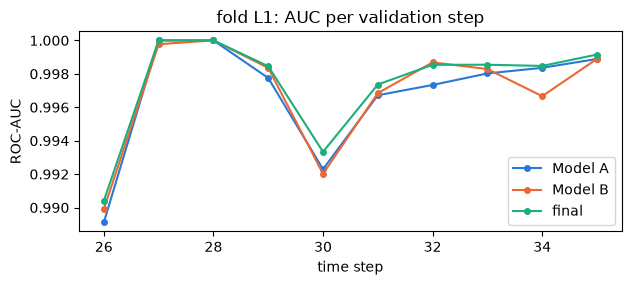

,ROC-AUC,PR-AUC,precision = recall at k,k
baseline (supervised LightGBM),0.9965,0.9865,0.9549,1307.0
PU learning,0.9926,0.9732,0.9112,1307.0
FINAL: Model A + Model B,0.9978,0.9924,0.9526,1307.0


In [12]:
if RUN_CV:
    assert (oof_a.txId.values == oof_b.txId.values).all()
    ra = oof_a.groupby("fold")["pred"].rank(pct=True).to_numpy()
    rb = oof_b.groupby("fold")["pred"].rank(pct=True).to_numpy()
    oof_final = oof_a.assign(pred=0.5 * ra + 0.5 * rb)
    rs = oof_single.groupby("fold")["pred"].rank(pct=True).to_numpy()
    oof_second = oof_a.assign(pred=0.5 * ra + 0.5 * rs)
    res = pd.DataFrame({"Model A: binary graph ensemble": summarise(oof_a), "Model B: 3-class ensemble": summarise(oof_b),
                        "single 3-class LightGBM": summarise(oof_single),
                        "FINAL: Model A + Model B": summarise(oof_final),
                        "SECOND: Model A + single 3-class LightGBM": summarise(oof_second)}).T
    display(res[["CV", "worst", "AP", *PRIMARY, "H"]].round(4))

    def per_step(o, fold):
        g = o[o.fold == fold]
        return g.groupby("time_step").apply(lambda s: roc_auc_score(s.y, s.pred) if s.y.nunique() == 2 else np.nan)
    fig, ax = plt.subplots(figsize=(7, 2.6))
    for o, name, c in [(oof_a, "Model A", "#2a78d6"), (oof_b, "Model B", "#eb6834"), (oof_final, "final", "#1baf7a")]:
        ax.plot(per_step(o, "L1"), "o-", color=c, label=name, ms=4)
    ax.set_title("fold L1: AUC per validation step"); ax.set_xlabel("time step"); ax.set_ylabel("ROC-AUC")
    ax.legend(); plt.show()

    def at_k(o, fold="L1"):
        # precision = recall when the alert budget k equals the number of illicit transactions
        g = o[o.fold == fold]; k = int(g.y.sum())
        top = g.pred.rank(ascending=False, method="first") <= k
        return {"ROC-AUC": roc_auc_score(g.y, g.pred), "PR-AUC": average_precision_score(g.y, g.pred),
                "precision = recall at k": (top & (g.y == 1)).sum() / k, "k": k}
    display(pd.DataFrame({"baseline (supervised LightGBM)": at_k(setup_oof["supervised"]), "PU learning": at_k(setup_oof["pu"]),
                          "FINAL: Model A + Model B": at_k(oof_final)}).T.round(4))

## 8. Final models and submission files
Both models are refitted on **all** training steps (1–35) with exactly the settings above, and each predicts the test
set. Two files are written, under the names they were uploaded with:
* `M26_M18_M24_1to1.csv`: **final submission**, equal-weight rank average of Model A and Model B;
* `M21_M18_M19_1to1.csv`: **second selected submission**, equal-weight rank average of Model A and the single
  3-class LightGBM (Model B's first member, so no extra model has to be trained).

In [13]:
t0 = time.time()
a_test, models_a = half_a(range(1, 36), te)
print(f"Model A fitted ({time.time() - t0:.0f}s)", flush=True)
b_test, b_members = half_b(range(1, 36), te)
print(f"Model B fitted ({time.time() - t0:.0f}s)", flush=True)
a_test, b_test, single_test = a_test[order], b_test[order], b_members[0][order]   # submission order
rank = lambda v: pd.Series(v).rank(pct=True).to_numpy()

subs = {OUT_FINAL: 0.5 * rank(a_test) + 0.5 * rank(b_test),          # Model A + Model B
        OUT_SECOND: 0.5 * rank(a_test) + 0.5 * rank(single_test)}    # Model A + single 3-class LightGBM
for path, target in subs.items():
    sub = pd.DataFrame({"index": test_index, "target": target})
    # format checks before uploading
    assert list(sub.columns) == list(sample.columns)
    assert len(sub) == len(sample) and (sub["index"].values == sample["index"].values).all()
    assert sub.target.between(0, 1).all() and sub.target.notna().all() and sub.target.nunique() > 1
    sub.to_csv(path, index=False)
    print("wrote", path, sub.shape)
print("Spearman on test: Model A vs Model B %.3f | final vs second submission %.3f"
      % (pd.Series(a_test).corr(pd.Series(b_test), method="spearman"),
         pd.Series(subs[OUT_FINAL]).corr(pd.Series(subs[OUT_SECOND]), method="spearman")))

Model A fitted (578s)


Model B fitted (889s)


wrote M26_M18_M24_1to1.csv (15329, 2)
wrote M21_M18_M19_1to1.csv (15329, 2)
Spearman on test: Model A vs Model B 0.908 | final vs second submission 0.994


In [14]:
# Reproducibility: compare with the files uploaded to Kaggle (if they are in a local submissions/ folder)
for path in [OUT_FINAL, OUT_SECOND]:
    uploaded = Path("submissions") / path.name
    if uploaded.exists():
        diff = np.abs(pd.read_csv(uploaded).target.values - pd.read_csv(path).target.values).max()
        print(f"{path.name}: max |difference| vs uploaded file {diff:.2e} ->", "IDENTICAL" if diff < 1e-9 else "DIFFERENT")
    else:
        print(f"{path.name}: uploaded file not found; skipped")

M26_M18_M24_1to1.csv: max |difference| vs uploaded file 0.00e+00 -> IDENTICAL
M21_M18_M19_1to1.csv: max |difference| vs uploaded file 0.00e+00 -> IDENTICAL


## 9. What the model relies on
Gain importance of Model A's all-features LightGBM (last seed). The features are anonymised, so this shows which
columns matter, not what they measure.

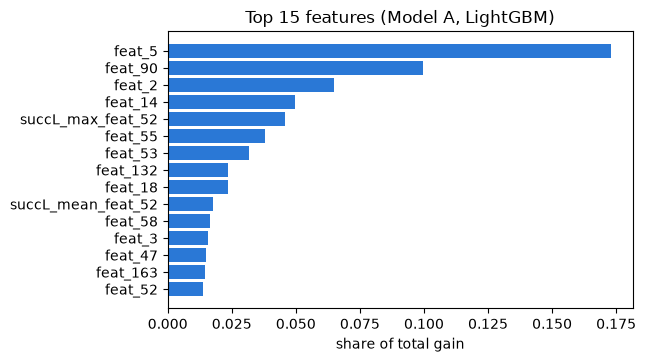

share of gain: features 1-93 0.71 | features 94-165 0.12 | labelled-neighbour features 0.18


In [15]:
m = models_a[0]
imp = pd.Series(m.booster_.feature_importance("gain"), index=G_ALL).sort_values(ascending=False)
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.barh(top.index, top.values / imp.sum(), color="#2a78d6")
ax.set_xlabel("share of total gain"); ax.set_title("Top 15 features (Model A, LightGBM)"); plt.show()
print(f"share of gain: features 1-93 {imp[LOCAL_FEATS].sum() / imp.sum():.2f} | features 94-165 "
      f"{imp[FEATS[93:]].sum() / imp.sum():.2f} | labelled-neighbour features {imp[list(GRAPH.columns)].sum() / imp.sum():.2f}")

## 10. Other things I tried
These come from my development experiments, evaluated on the same folds (CV = mean of L1–L4).

| Idea | CV | Public | Outcome |
|---|---|---|---|
| Logistic regression (quantile-scaled) | 0.9657 | – | far behind trees |
| Random forest / ExtraTrees | 0.9916 / 0.9943 | – | behind boosting |
| XGBoost (alone / added to the ensemble) | 0.9970 / 0.9987 | – | ρ = 0.994 with the ensemble, nothing new |
| Structural graph features (degree, PageRank, k-core, ...) | 0.9974 | – | lowered the long-horizon fold (0.880 vs 0.901) |
| Ratio features built from integer-valued count columns | 0.9974 | – | no gain |
| Neighbour-score smoothing, per-step normalisation, self-training | – | – | no gain |
| 3-class model with graph features | 0.9930 | – | clearly worse |
| Isolation Forest (no labels at all) | 0.886* | 0.82328 | *as an anomaly score it gives AUC 0.11: illicit transactions are the *ordinary* ones |
| Graph neural net (MLP on X, AX, A²X) | 0.9909 | 0.92103 | neighbourhoods are half missing in test (§1.1) |

The last two were deliberate exploration submissions. Both fail for the same reasons the final model is built the
way it is: the labelled population changes over time (§4), and neighbourhood features built from unlabelled
neighbours do not carry over to the test period (§2.2).

## 11. Public score of each development step
The scores below are the ROC-AUC values Kaggle reported on the public 30% of the test set for each submission, in the
order they were made (they cannot be recomputed here, since the test labels are hidden). Each step changed one thing
relative to an earlier one. This is Figure 2 of the report.

In [ ]:
steps = [("Baseline: LightGBM, raw features", 0.94499, "supervised"),
         ("+ unlabelled as weak illicit (PU)", 0.93169, "PU"),
         ("Baseline minus 15 drifting features", 0.94279, "supervised"),
         ("+ unlabelled as weak licit (w = 0.01)", 0.95282, "weak licit"),
         ("4-model ensemble, weak licit (w = 0.01)", 0.95562, "weak licit"),
         ("4-model ensemble, weak licit (w = 0.05)", 0.96024, "weak licit"),
         ("3-class LightGBM (all unlabelled rows)", 0.96014, "3-class"),
         ("+ recent unlabelled rows only", 0.96273, "weak licit"),
         ("+ licit importance weights", 0.96361, "weak licit"),
         ("3-class LightGBM (recent unlabelled rows)", 0.96462, "3-class"),
         ("+ labelled-neighbour features = Model A", 0.96576, "weak licit"),
         ("Model A + 3-class LightGBM  [2nd selection]", 0.96805, "blend"),
         ("Model A + Model B  [final]", 0.96843, "blend")]
colours = {"supervised": "#2a78d6", "PU": "#eb6834", "weak licit": "#1baf7a", "3-class": "#4a3aa7", "blend": "#c4364a"}
fig, ax = plt.subplots(figsize=(7, 3.6))
for i, (name, score, kind) in enumerate(steps):
    ax.barh(i, score - 0.925, left=0.925, color=colours[kind], height=0.62)
    ax.text(score + 0.0006, i, f"{score:.5f}", va="center", fontsize=7.5)
ax.set_yticks(range(len(steps)), [s[0] for s in steps], fontsize=7.5)
ax.invert_yaxis(); ax.set_xlim(0.925, 0.975)
ax.set_xlabel("ROC-AUC on the public 30% of the hidden test set")
ax.set_title("Development steps in submission order (one change per step)", loc="left")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in colours.items()], loc="upper right", fontsize=7)
plt.show()